In [1]:
%pip install ultralytics roboflow pandas matplotlib seaborn pyyaml -q

import os
import yaml
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from collections import Counter

Note: you may need to restart the kernel to use updated packages.


In [2]:
from ultralytics import YOLO 
from roboflow import Roboflow

In [3]:
rf = Roboflow(api_key="Qb9gtEx8C69ECxGhT4js") 
project = rf.workspace("robotics-v9fnj").project("lettuce-growth-stage-qld0b")

loading Roboflow workspace...
loading Roboflow project...


In [ ]:
# Download the dataset in the YOLOv8 format
dataset = project.version(1).download("yolov8")
data_yaml_path = os.path.join(dataset.location, "data.yaml")

# Load class names (growth stages)
with open(data_yaml_path, "r") as f:
    data_cfg = yaml.safe_load(f)

class_names = data_cfg.get("names", [])
if isinstance(class_names, dict):
    class_names = list(class_names.values())

In [5]:
def run_yolo_eda(dataset_loc, classes):
    """
    Parses the YOLO .txt label files to count the number of bounding boxes 
    per lettuce growth stage. This identifies class imbalances in the dataset.
    """
    print("\n" + "="*65)
    print("      EXPLORATORY DATA ANALYSIS: LETTUCE GROWTH STAGES      ")
    print("="*65)
    
    split_dir = os.path.join(dataset_loc, "train")
    lbl_dir = os.path.join(split_dir, "labels")
    
    if not os.path.exists(lbl_dir):
        print("Labels directory not found. Ensure dataset downloaded correctly.")
        return

    class_counts = Counter()
    total_boxes = 0

    # Read every YOLO label text file
    for lbl_file in os.listdir(lbl_dir):
        if not lbl_file.endswith(".txt"): continue
            
        with open(os.path.join(lbl_dir, lbl_file), "r") as f:
            for line in f:
                parts = line.strip().split()
                if len(parts) > 0:
                    cls_id = int(parts[0])
                    class_counts[cls_id] += 1
                    total_boxes += 1

    print(f"Total Bounding Boxes in Training Set: {total_boxes}")
    print("-" * 65)
    print(f"{'Class ID':<10} {'Stage Name':<18} {'Box Count':<12} {'Percentage'}")
    print("-" * 65)
    
    for cls_id in range(len(classes)):
        count = class_counts[cls_id]
        pct = (count / total_boxes * 100) if total_boxes > 0 else 0
        print(f"{cls_id:<10} {classes[cls_id]:<18} {count:<12} {pct:.1f}%")

# Execute the EDA function
run_yolo_eda(dataset.location, class_names)


      EXPLORATORY DATA ANALYSIS: LETTUCE GROWTH STAGES      
Total Bounding Boxes in Training Set: 623
-----------------------------------------------------------------
Class ID   Stage Name         Box Count    Percentage
-----------------------------------------------------------------
0          Harvest Stage      218          35.0%
1          Seedling Stage     209          33.5%
2          Vegetative Stage   196          31.5%


In [6]:
models_to_test = {
    "YOLOv8n": "yolov8n.pt",   
    "YOLOv9t": "yolov9t.pt",   # Introduces PGI for better small object detection
    "YOLOv10n": "yolov10n.pt", # NMS-free architecture (highly optimized for low latency)
    "YOLO11n": "yolo11n.pt"    # 2024 SOTA architecture (highest parameter efficiency)
}

In [7]:
results_data = []

print("\n--- Starting Model Benchmarking ---")

for model_name, weights in models_to_test.items():
    print("\n" + "="*50)
    print(f" Training and Evaluating: {model_name} ")
    print("="*50)
    
    # 3.1 Initialize the specific YOLO architecture
    model = YOLO(weights)
    
    # 3.2 Train the model https://docs.ultralytics.com/modes/train
    model.train(
        data=data_yaml_path,
        epochs=30,             
        imgsz=320,             # Smaller image size for edge-device optimization
        batch=16,              
        device="cpu",          # IMPORTANT: Change to 0 if using a GPU in Google Colab!
        name=f"lettuce_{model_name.lower()}", # Saves outputs to runs/detect/lettuce_yolov8n
        patience=10,           # Early stopping to prevent overfitting
        plots=True             # Generates Confusion Matrices, PR curves, etc. [2]
    )
    
    # 3.3 Validate the model on the unseen test split
    print(f"\n--- Evaluating {model_name} on Test Set ---")
    metrics = model.val(
        data=data_yaml_path,
        split="test",
        imgsz=320
    )
    #https://docs.ultralytics.com/modes/train

#https://docs.ultralytics.com/guides/yolo-performance-metrics 
#https://docs.ultralytics.com/modes/val
    # 3.4 Extract Performance Metrics (Reference: GeeksForGeeks Computer Vision Guidelines)
    # mAP@50: Mean Average Precision at an Intersection over Union (IoU) threshold of 50%.
    map50 = metrics.box.map50
    
    # mAP@50-95: A stricter metric requiring the bounding box to be almost perfect.
    map50_95 = metrics.box.map  
    
    # Precision: Out of all the times the model predicted "lettuce", how often was it right?
    precision = metrics.box.p.mean() if len(metrics.box.p) > 0 else 0
    
    # Recall: Out of all the actual lettuce plants in the image, how many did it find?
    recall = metrics.box.r.mean() if len(metrics.box.r) > 0 else 0
    
    # Inference Speed: Crucial for real-time robotic deployment [1]
    inference_speed_ms = metrics.speed['inference']
    
    # Extract total parameter count using PyTorch backend logic
    try:
        total_params = sum(p.numel() for p in model.model.parameters())
    except Exception:
        total_params = 0
        
    # 3.5 Store results in a dictionary https://medium.com/@chinmayiadsul/my-yolo-models-talking-here-s-what-it-s-really-saying-85298b256e34 / https://docs.ultralytics.com/modes/predict
    results_data.append({
        "Model": model_name,
        "mAP@50 (%)": round(map50 * 100, 2),
        "mAP@50-95 (%)": round(map50_95 * 100, 2),
        "Precision (%)": round(precision * 100, 2),
        "Recall (%)": round(recall * 100, 2),
        "Inference (ms)": round(inference_speed_ms, 2),
        "Parameters (M)": round(total_params / 1_000_000, 2)
    })


--- Starting Model Benchmarking ---

 Training and Evaluating: YOLOv8n 
New https://pypi.org/project/ultralytics/8.4.178 available  Update with 'pip install -U ultralytics'
Ultralytics 8.4.173  Python-3.13.16 torch-2.14.1+cpu CPU (13th Gen Intel Core i7-1355U)
engine\trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=c:\Research_RPDA_8412w\Lettuce-Growth-Stage-1\data.yaml, degrees=0.0, deterministic=True, device=cpu, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=30, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=320, iou=0.7, kobj=1.0, line_wid

In [8]:
print("\n" + "="*80)
print("             FINAL BENCHMARK RESULTS (TEST SET)              ")
print("="*80)

# Convert dictionary list to a Pandas DataFrame for clean formatting
df_results = pd.DataFrame(results_data)
df_results = df_results.sort_values(by="mAP@50-95 (%)", ascending=False)
print(df_results.to_string(index=False))

# Save the tabular data to a CSV for your research paper
csv_filename = "yolo_benchmark_results.csv"
df_results.to_csv(csv_filename, index=False)
print(f"\n[+] Results successfully saved to '{csv_filename}'")


             FINAL BENCHMARK RESULTS (TEST SET)              
   Model  mAP@50 (%)  mAP@50-95 (%)  Precision (%)  Recall (%)  Inference (ms)  Parameters (M)
YOLOv10n        99.5          94.21          98.99       100.0           38.09            2.71
 YOLO11n        99.5          93.12          99.22       100.0           24.47            2.59
 YOLOv8n        99.5          92.53          99.17       100.0           20.47            3.01
 YOLOv9t        99.5          91.34          98.85       100.0           36.15            2.01

[+] Results successfully saved to 'yolo_benchmark_results.csv'


[+] Visual plot saved to 'accuracy_vs_latency_bubble_chart.png'


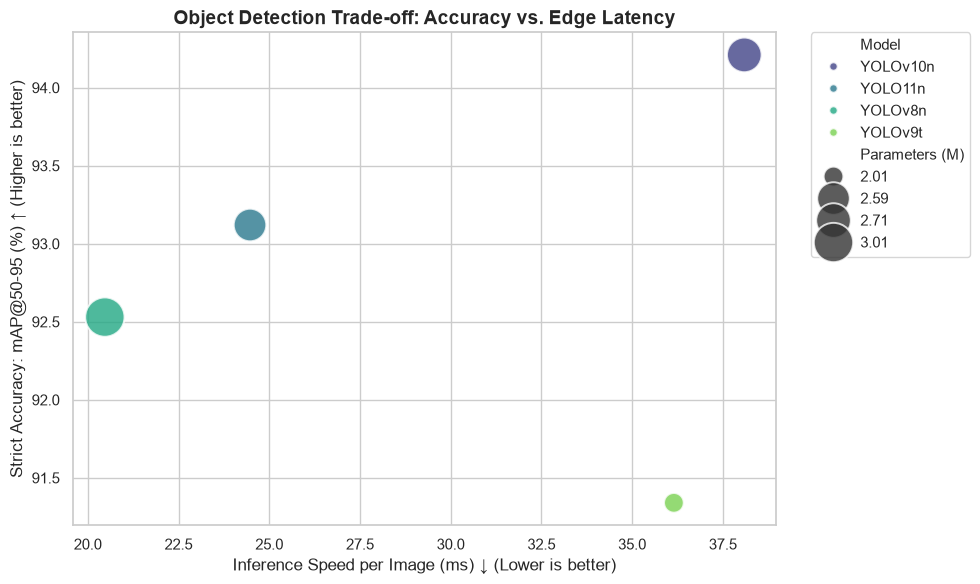

: 

In [ ]:
sns.set_theme(style="whitegrid")
plt.figure(figsize=(10, 6))

# Create a scatter plot where bubble size represents the Parameter count
scatter = sns.scatterplot(
    data=df_results, 
    x="Inference (ms)", 
    y="mAP@50-95 (%)", 
    hue="Model", 
    size="Parameters (M)", 
    sizes=(200, 800), # Adjust bubble size range
    alpha=0.8,
    palette="viridis"
)

plt.title("Object Detection Trade-off: Accuracy vs. Edge Latency", fontsize=14, fontweight='bold')
plt.xlabel("Inference Speed per Image (ms) ↓ (Lower is better)", fontsize=12)
plt.ylabel("Strict Accuracy: mAP@50-95 (%) ↑ (Higher is better)", fontsize=12)

# Move the legend outside the plot
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left', borderaxespad=0)
plt.tight_layout()

# Save the plot
plot_filename = "accuracy_vs_latency_bubble_chart.png"
plt.savefig(plot_filename, dpi=300)
print(f"[+] Visual plot saved to '{plot_filename}'")

In [7]:
from ultralytics import YOLO

# Point to the actual path of the trained weights
model = YOLO("runs/detect/lettuce_yolo11n/weights/best.pt")

# Export to NCNN
model.export(format="ncnn")

Ultralytics 8.4.173  Python-3.13.16 torch-2.14.1+cpu CPU (13th Gen Intel Core i7-1355U)
YOLO11n summary (fused): 100 layers, 2,582,737 parameters, 0 gradients, 1.6 GFLOPs

PyTorch: starting from 'runs\detect\lettuce_yolo11n\weights\best.pt' with input shape (1, 3, 320, 320) BCHW and output shape(s) (1, 7, 2100) (5.2 MB)

NCNN: starting export with NCNN 1.0.20260526 and PNNX 20260526...


c:\Users\jessi\AppData\Local\Programs\Python\Python313\Lib\site-packages\torch\jit\_trace.py:1006: FutureWarning: `torch.jit.trace` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(
c:\Users\jessi\AppData\Local\Programs\Python\Python313\Lib\site-packages\torch\jit\_trace.py:1145: FutureWarning: `torch.jit.trace_method` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


NCNN: export success  23.5s, saved as 'runs\detect\lettuce_yolo11n\weights\best_ncnn_model' (10.0 MB)

Export complete (24.0s)
Results saved to C:\Research_RPDA_8412w\runs\detect\lettuce_yolo11n\weights\best_ncnn_model
Predict:         yolo predict task=detect model=runs\detect\lettuce_yolo11n\weights\best_ncnn_model imgsz=320 
Validate:        yolo val task=detect model=runs\detect\lettuce_yolo11n\weights\best_ncnn_model imgsz=320 data=c:\Research_RPDA_8412w\Lettuce-Growth-Stage-1\data.yaml  
Visualize:       https://netron.app


'runs\\detect\\lettuce_yolo11n\\weights\\best_ncnn_model'

In [8]:
from ultralytics import YOLO

# Point to the actual path of the trained weights in your runs folder
model = YOLO("runs/detect/lettuce_yolo11n/weights/best.pt")

# Export to NCNN
model.export(format="ncnn")

Ultralytics 8.4.173  Python-3.13.16 torch-2.14.1+cpu CPU (13th Gen Intel Core i7-1355U)
YOLO11n summary (fused): 100 layers, 2,582,737 parameters, 0 gradients, 1.6 GFLOPs

PyTorch: starting from 'runs\detect\lettuce_yolo11n\weights\best.pt' with input shape (1, 3, 320, 320) BCHW and output shape(s) (1, 7, 2100) (5.2 MB)

NCNN: starting export with NCNN 1.0.20260526 and PNNX 20260526...


c:\Users\jessi\AppData\Local\Programs\Python\Python313\Lib\site-packages\torch\jit\_trace.py:1006: FutureWarning: `torch.jit.trace` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(
c:\Users\jessi\AppData\Local\Programs\Python\Python313\Lib\site-packages\torch\jit\_trace.py:1145: FutureWarning: `torch.jit.trace_method` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


NCNN: export success  5.9s, saved as 'runs\detect\lettuce_yolo11n\weights\best_ncnn_model' (10.0 MB)

Export complete (6.2s)
Results saved to C:\Research_RPDA_8412w\runs\detect\lettuce_yolo11n\weights\best_ncnn_model
Predict:         yolo predict task=detect model=runs\detect\lettuce_yolo11n\weights\best_ncnn_model imgsz=320 
Validate:        yolo val task=detect model=runs\detect\lettuce_yolo11n\weights\best_ncnn_model imgsz=320 data=c:\Research_RPDA_8412w\Lettuce-Growth-Stage-1\data.yaml  
Visualize:       https://netron.app


'runs\\detect\\lettuce_yolo11n\\weights\\best_ncnn_model'